In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data\Wine.csv")

<>:7: SyntaxWarning: invalid escape sequence '\W'
<>:7: SyntaxWarning: invalid escape sequence '\W'
C:\Users\neelp\AppData\Local\Temp\ipykernel_21320\3017780075.py:7: SyntaxWarning: invalid escape sequence '\W'
  df = pd.read_csv("../data\Wine.csv")


In [5]:
target_col = "Customer_Segment"   # Change this if your target column has another name

X = df.drop(columns=[target_col])
y = df[target_col]

# Convert categorical input columns into numeric dummy variables, if any
X = pd.get_dummies(X, drop_first=True)

# Encode target labels if they are text
if y.dtype == "object" or str(y.dtype).startswith("category"):
    le = LabelEncoder()
    y = le.fit_transform(y.astype(str))

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (142, 13)
Testing data: (36, 13)


In [7]:
# Random Forest and the boosting models below are tree-based, so scaling is not necessary.
# Keep the original feature values.

Random Forest (Bagging-based ensemble)

In [8]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      1.00      1.00        14
           3       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



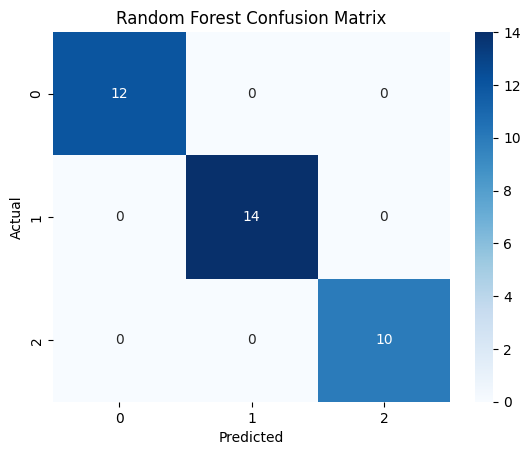

In [9]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Random Forest feature importance

In [15]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

print(importance.head(10))

Color_Intensity    0.187580
Flavanoids         0.159561
Proline            0.146799
Alcohol            0.117913
Hue                0.101538
OD280              0.096301
Total_Phenols      0.041514
Magnesium          0.040131
Malic_Acid         0.033894
Ash_Alcanity       0.025471
dtype: float64


## Train AdaBoost (Boosting)

In [16]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

ada.fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ada))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_ada))

AdaBoost Accuracy: 0.9722222222222222

Classification Report:
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        12
           2       1.00      0.93      0.96        14
           3       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



## Train Gradient Boosting

In [17]:
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 0.9444444444444444

Classification Report:
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        12
           2       0.93      0.93      0.93        14
           3       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



## Compare ensemble models

               Model  Accuracy
0      Random Forest  1.000000
1           AdaBoost  0.972222
2  Gradient Boosting  0.944444


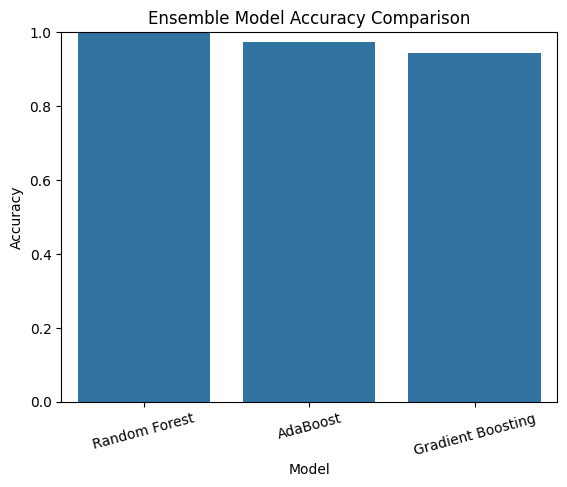

In [13]:
results = pd.DataFrame({
    "Model": ["Random Forest", "AdaBoost", "Gradient Boosting"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_ada),
        accuracy_score(y_test, y_pred_gb)
    ]
})

print(results)
sns.barplot(data=results, x="Model", y="Accuracy")
plt.ylim(0, 1)
plt.title("Ensemble Model Accuracy Comparison")
plt.xticks(rotation=15)
plt.show()

## Analysis / Conclusion

- Random Forest is a bagging-based ensemble: many decision trees are trained using bootstrap samples and their predictions are combined.
- AdaBoost trains weak learners sequentially, giving more attention to observations that were previously misclassified.
- Gradient Boosting adds learners sequentially to reduce the errors of the current ensemble.
- Compare accuracy and the classification reports. The best model is not determined by accuracy alone if the classes are imbalanced.